### VIX index correlation V3

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import spearmanr
from scipy.stats import pearsonr
from sklearn.metrics import roc_auc_score
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

In [3]:
# Date range for fetching API s
start = '2010-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

#### VIX時系列を取得

In [4]:
vix_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^VIX",
    market=None,
)
vix_df.tail()

取得件数: 4437


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4432,1285479,^VIX,None,2026-10-16,19.990000,22.309999,15.720000,16.020000,0,15.948,...,15.026457,27.524972,True,15.948,NaN,NaN,NaN,NaN,NaN,False
4433,1318186,^VIX,None,2026-10-19,18.440001,18.930000,17.389999,18.370001,0,16.544,...,14.980537,34.171433,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4434,1322446,^VIX,None,2026-10-20,17.309999,19.129999,17.250000,18.420000,0,17.106,...,14.941097,37.287629,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4435,1332259,^VIX,None,2026-10-21,16.680000,17.580000,16.510000,17.250000,0,17.522,...,14.939329,40.258687,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4436,1332252,^VIX,None,2026-10-22,19.030001,20.309999,17.709999,18.290001,0,17.670,...,14.930694,43.767609,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500時系列を取得

In [5]:
sp500_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^GSPC",
    market=None,
)
sp500_df.tail()

取得件数: 4435


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4430,1318182,^GSPC,None,2026-10-16,7659.439941,7756.839844,7631.770020,7745.319824,5482060000,7763.024023,...,7653.598617,9.433962,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4431,1318187,^GSPC,None,2026-10-19,7690.729980,7731.180176,7684.790039,7702.770020,4587260000,7740.970020,...,7660.913979,12.037907,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4432,1322447,^GSPC,None,2026-10-20,7712.569824,7748.419922,7668.029785,7679.009766,5004770000,7717.717969,...,7667.092991,10.475540,False,NaN,7723.472031,NaN,NaN,NaN,NaN,False
4433,1322449,^GSPC,None,2026-10-21,NaN,NaN,NaN,NaN,2889474000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4434,1332253,^GSPC,None,2026-10-22,7663.430176,7702.939941,7637.359863,7694.620117,3559453000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Nasdaq100時系列を取得

In [6]:
qqq_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^IXIC",
    market=None,
)
qqq_df.tail()

取得件数: 4258


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4253,1322441,^IXIC,None,2026-10-16,26140.029297,26674.660156,26023.099609,26652.980469,9505000000,26911.326172,...,26465.504547,52.565525,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4254,1322442,^IXIC,None,2026-10-19,26430.890625,26613.150391,26344.669922,26395.289062,7537660000,26719.882031,...,26505.571508,51.967899,False,NaN,26916.25625,NaN,NaN,NaN,NaN,False
4255,1322448,^IXIC,None,2026-10-20,26424.820312,26601.710938,26179.730469,26332.919922,7660360000,26558.719922,...,26526.314282,46.008708,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4256,1322483,^IXIC,None,2026-10-21,NaN,NaN,NaN,NaN,6898345000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4257,1332254,^IXIC,None,2026-10-22,26008.859375,26359.406250,25918.091797,26308.406250,7832683000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### UVXY時系列を取得

In [7]:
uvxy_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="UVXY",
    market=None,
)
uvxy_df.tail()

取得件数: 3785


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3780,1326264,UVXY,None,2026-10-16,18.500000,19.580000,15.840000,16.059999,43969800,16.230,...,16.9468,-95.594638,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3781,1326265,UVXY,None,2026-10-19,17.379999,17.730000,16.870001,17.520000,18879800,16.520,...,16.8940,-92.930931,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3782,1326266,UVXY,None,2026-10-20,17.180000,18.139999,16.809999,17.870001,17214800,16.916,...,16.8868,-89.780586,True,16.916,NaN,NaN,NaN,NaN,NaN,False
3783,1326267,UVXY,None,2026-10-21,16.799999,17.420000,16.709999,16.870001,14922300,17.090,...,16.8416,-88.875608,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3784,1332255,UVXY,None,2026-10-22,18.410000,18.969999,17.170000,17.459999,23872700,17.156,...,16.8448,-85.575856,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### SVXY時系列を取得

In [8]:
svxy_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="SVXY",
    market=None,
)
svxy_df.tail()

取得件数: 3785


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3780,1330048,SVXY,None,2026-10-16,62.060001,65.500000,60.570000,65.180000,13662000,65.019999,...,63.288037,94.335354,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3781,1330049,SVXY,None,2026-10-19,63.259998,63.849998,62.869999,63.090000,3850300,64.598000,...,63.430980,91.381371,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3782,1330050,SVXY,None,2026-10-20,63.540001,63.990002,62.369999,62.689999,2225300,64.030000,...,63.423886,87.483992,False,NaN,64.1664,NaN,NaN,NaN,NaN,False
3783,1330051,SVXY,None,2026-10-21,NaN,NaN,NaN,NaN,1610778,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3784,1332256,SVXY,None,2026-10-22,61.980000,63.520000,61.259998,63.250000,3109700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VXX時系列を取得

In [9]:
vxx_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="VXX",
    market=None,
)
vxx_df.tail()

取得件数: 2198


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
2193,1332245,VXX,None,2026-10-16,18.379999,19.260000,16.670000,16.809999,44429900,16.936,...,16.952281,-94.168872,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2194,1332246,VXX,None,2026-10-19,17.790001,18.010000,17.434999,17.865000,24216200,17.143,...,16.985198,-91.564928,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2195,1332247,VXX,None,2026-10-20,17.570000,18.280001,17.379999,18.080000,13604000,17.421,...,16.985904,-88.474345,True,17.421,NaN,NaN,NaN,NaN,NaN,False
2196,1332248,VXX,None,2026-10-21,17.389999,17.785000,17.299999,17.400000,10846000,17.545,...,16.987596,-87.526680,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2197,1332257,VXX,None,2026-10-22,18.480000,18.865000,17.639999,17.770000,19823900,17.585,...,16.987295,-84.299496,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VIXM時系列を取得

In [10]:
vixm_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="VIXM",
    market=None,
)
vixm_df.tail()

取得件数: 3974


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3969,1289449,VIXM,None,2026-10-16,12.84,13.13,12.64,12.69,463000,12.788,...,12.757745,-94.843336,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3970,1332249,VIXM,None,2026-10-19,12.90,12.92,12.76,12.89,307900,12.798,...,12.768912,-94.664048,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3971,1332250,VIXM,None,2026-10-20,13.00,13.07,12.86,13.07,456400,12.876,...,12.778590,-93.229745,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3972,1332251,VIXM,None,2026-10-21,NaN,NaN,NaN,NaN,510088,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3973,1332258,VIXM,None,2026-10-22,13.21,13.30,13.01,13.01,307700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VIXの各日時点のフィボナッチリトレースメントをローリング計算

In [11]:
fibonacci_retracement_df = fibonacci_retracement.fibonacci_retracement_for_timeseries(
    df=vix_df,
    lookback=120,
)
fibonacci_retracement_df.tail()

,date,close,fib_trend,fib_top,fib_bottom,fib_retracement_0.000,fib_retracement_0.236,fib_retracement_0.382,fib_retracement_0.500,fib_retracement_0.618,fib_retracement_0.786,fib_retracement_1.000
4312,2026-10-16,16.020000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4313,2026-10-19,18.370001,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4314,2026-10-20,18.420000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4315,2026-10-21,17.250000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4316,2026-10-22,18.290001,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25


#### VIXの各日時点のフィボナッチエクステンションをローリング計算

In [12]:
fibonacci_extension_df = fibonacci_extension_v2.fibonacci_extension_for_timeseries(
    df=vix_df,
    lookback=120,
    extension_direction="up"
)
fibonacci_extension_df.tail()

,date,close,fib_trend,fib_top,fib_bottom,fib_extension_1.000,fib_extension_1.272,fib_extension_1.618,fib_extension_2.000,fib_extension_2.618,fib_extension_4.236,distance_ext_1272,distance_ext_1618,distance_ext_2000,distance_ext_2618,distance_ext_4236
4312,2026-10-16,16.020000,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-7.161200,-9.617800,-12.330000,-16.717800,-28.205601
4313,2026-10-19,18.370001,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.811199,-7.267799,-9.980000,-14.367800,-25.855600
4314,2026-10-20,18.420000,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.761200,-7.217800,-9.930000,-14.317801,-25.805601
4315,2026-10-21,17.250000,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-5.931200,-8.387800,-11.100000,-15.487801,-26.975601
4316,2026-10-22,18.290001,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.891199,-7.347799,-10.059999,-14.447800,-25.935600


#### 1. 分析目的

##### 目的

VIX関連ETFの出来高異常が
将来のVIX急騰イベントを
事前に示唆しているか確認する。

回帰問題ではなく
分類問題として評価する。

##### データ統合

In [13]:
# データフレームのコピーを作成
vix_work = vix_df.copy()
sp500_work = sp500_df.copy()
qqq_work = qqq_df.copy()
uvxy_work = uvxy_df.copy()
svxy_work = svxy_df.copy()
vxx_work = vxx_df.copy()
vixm_work = vixm_df.copy()
# 必要列のみ抽出
vix_work = vix_work[
    [
        "date",
        "close"
    ]
].rename(
    columns={
        "close": "vix"
    }
)
# S&P500の必要列のみ抽出
sp500_work = sp500_work[
    [
        "date",
        "close"
    ]
].rename(
    columns={
        "close": "sp500"
    }
)
# QQQの必要列のみ抽出
qqq_work = qqq_work[
    [
        "date",
        "close"
    ]
].rename(
    columns={
        "close": "qqq"
    }
)
# UVXYの必要列のみ抽出
uvxy_work = uvxy_work[
    [
        "date",
        "close",
        "volume"
    ]
].rename(
    columns={
        "close": "uvxy",
        "volume": "uvxy_volume"
    }
)
# SVXYの必要列のみ抽出
svxy_work = svxy_work[
    [
        "date",
        "close",
        "volume"
    ]
].rename(
    columns={
        "close": "svxy",
        "volume": "svxy_volume"
    }
)
# VXXの必要列のみ抽出
vxx_work = vxx_work[
    [
        "date",
        "close",
        "volume"
    ]
].rename(
    columns={
        "close": "vxx",
        "volume": "vxx_volume"
    }
)
# VIXMの必要列のみ抽出
vixm_work = vixm_work[
    [
        "date",
        "close",
        "volume"
    ]
].rename(
    columns={
        "close": "vixm",
        "volume": "vixm_volume"
    }
)
# 結合用のデータフレームを作成
research_df = (
    vix_work
    .merge(
        sp500_work,
        on="date",
        how="left"
    )
    .merge(
        qqq_work,
        on="date",
        how="left"
    )
    .merge(
        uvxy_work,
        on="date",
        how="left"
    )
    .merge(
        svxy_work,
        on="date",
        how="left"
    )
    .merge(
        vxx_work,
        on="date",
        how="left"
    )
    .merge(
        vixm_work,
        on="date",
        how="left"
    )
)
# 結合結果の形状を確認
print(research_df.shape)
display(
    research_df.head()
)

(4437, 12)


,date,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,vixm,vixm_volume
0,2009-03-09,49.349998,680.760010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2009-03-10,49.680000,679.280029,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2009-03-11,43.349998,719.590027,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2009-03-12,43.529999,720.890015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2009-03-13,40.990002,751.969971,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##### Fibonacci結果を統合


In [14]:
# Fibonacci系列を index 基準で結合（lookback 分の先頭行は NaN になる）
fib_columns = {
    "fib_retracement": fibonacci_retracement_df["fib_retracement_0.618"],
    "fib_extension": fibonacci_extension_df["fib_extension_1.618"],
    "fib_top": fibonacci_extension_df["fib_top"],
    "fib_bottom": fibonacci_extension_df["fib_bottom"],
}

for column, series in fib_columns.items():
    research_df[column] = series.reindex(research_df.index)

# 結合結果を表示
display(
    research_df[
        [
            "date",
            "vix",
            "fib_retracement",
            "fib_extension",
        ]
    ].tail()
)

,date,vix,fib_retracement,fib_extension
4432,2026-10-16,16.020000,NaN,NaN
4433,2026-10-19,18.370001,NaN,NaN
4434,2026-10-20,18.420000,NaN,NaN
4435,2026-10-21,17.250000,NaN,NaN
4436,2026-10-22,18.290001,NaN,NaN


##### GapRatio特徴量作成

In [15]:
# ギャップとギャップ比率を計算
research_df["gap_ret"] = (
    research_df["fib_retracement"]
    -
    research_df["vix"]
)
# ギャップの比率を計算するための準備
research_df["gap_ext"] = (
    research_df["fib_extension"]
    -
    research_df["vix"]
)
# ギャップ比率を計算
research_df["gap_ret_ratio"] = (
    research_df["gap_ret"]
    /
    research_df["vix"]
)
# ギャップ比率を計算するための準備
research_df["gap_ext_ratio"] = (
    research_df["gap_ext"]
    /
    research_df["vix"]
)
# ギャップ比率の表示
display(
    research_df[
        [
            "date",
            "gap_ret_ratio",
            "gap_ext_ratio"
        ]
    ].tail()
)

,date,gap_ret_ratio,gap_ext_ratio
4432,2026-10-16,NaN,NaN
4433,2026-10-19,NaN,NaN
4434,2026-10-20,NaN,NaN
4435,2026-10-21,NaN,NaN
4436,2026-10-22,NaN,NaN


##### GapVelocity・GapAcceleration作成

In [16]:
# ギャップ比率の変化率（速度）と加速度を計算
research_df["gap_velocity"] = (
    research_df["gap_ext_ratio"]
    .diff()
)
# ギャップ比率の変化率（速度）の表示
research_df["gap_acceleration"] = (
    research_df["gap_velocity"]
    .diff()
)

##### 出来高特徴量作成

In [17]:
volume_cols = [
    "uvxy_volume",
    "svxy_volume",
    "vxx_volume",
    "vixm_volume"
]
# 各銘柄の出来高の20日移動平均と比率を計算
for col in volume_cols:
    # 20日移動平均を計算
    research_df[f"{col}_ma20"] = (
        research_df[col]
        .rolling(20)
        .mean()
    )
    # 出来高と移動平均の比率を計算
    research_df[f"{col}_ratio"] = (
        research_df[col]
        /
        research_df[f"{col}_ma20"]
    )

##### 出来高Z-Score作成

In [18]:
for col in volume_cols:
    # 60日移動平均と標準偏差を計算
    rolling_mean = (
        research_df[col]
        .rolling(60)
        .mean()
    )
    # 計算結果を確認
    rolling_std = (
        research_df[col]
        .rolling(60)
        .std()
    )

    # Zスコアを計算
    research_df[f"{col}_z"] = (
        research_df[col]
        -
        rolling_mean
    ) / rolling_std

##### Fear Flow作成

In [19]:
# 恐怖フローのバランスを計算
research_df["fear_flow_balance"] = (
    research_df["uvxy_volume_z"]
    -
    research_df["svxy_volume_z"]
)
# 恐怖フローのバランス2を計算
research_df["fear_flow_balance_2"] = (
    research_df["vxx_volume_z"]
    -
    research_df["svxy_volume_z"]
)
# 恐怖フローのバランスを表示
display(
    research_df[
        [
            "date",
            "fear_flow_balance",
            "fear_flow_balance_2"
        ]
    ].tail()
)

,date,fear_flow_balance,fear_flow_balance_2
4432,2026-10-16,NaN,NaN
4433,2026-10-19,NaN,NaN
4434,2026-10-20,NaN,NaN
4435,2026-10-21,NaN,NaN
4436,2026-10-22,NaN,NaN


##### 未来目的変数作成

In [20]:
for period in [1, 2, 3, 4, 5, 10, 20, 40]:
    research_df[
        f"vix_{period}d_return"
    ] = (
        research_df["vix"]
        .shift(-period)
        /
        research_df["vix"]
        -
        1.0
    )
research_df.tail()

,date,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,...,fear_flow_balance,fear_flow_balance_2,vix_1d_return,vix_2d_return,vix_3d_return,vix_4d_return,vix_5d_return,vix_10d_return,vix_20d_return,vix_40d_return
4432,2026-10-16,16.020000,7745.319824,26652.980469,16.059999,43969800.0,65.180000,13662000.0,16.809999,44429900.0,...,NaN,NaN,0.146692,0.149813,0.076779,0.141698,NaN,NaN,NaN,NaN
4433,2026-10-19,18.370001,7702.770020,26395.289062,17.520000,18879800.0,63.090000,3850300.0,17.865000,24216200.0,...,NaN,NaN,0.002722,-0.060969,-0.004355,NaN,NaN,NaN,NaN,NaN
4434,2026-10-20,18.420000,7679.009766,26332.919922,17.870001,17214800.0,62.689999,2225300.0,18.080000,13604000.0,...,NaN,NaN,-0.063518,-0.007058,NaN,NaN,NaN,NaN,NaN,NaN
4435,2026-10-21,17.250000,NaN,NaN,16.870001,14922300.0,NaN,1610778.0,17.400000,10846000.0,...,NaN,NaN,0.060290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4436,2026-10-22,18.290001,7694.620117,26308.406250,17.459999,23872700.0,63.250000,3109700.0,17.770000,19823900.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### 2. 分類対象作成

##### 目的

VIX急騰イベントを
二値分類問題へ変換する。

In [21]:
SPIKE_THRESHOLDS = [0.05, 0.10, 0.20]
FORECAST_PERIODS = [1, 2, 3, 4, 5]
# 各予測期間およびしきい値について、スパイク列を生成する
for period in FORECAST_PERIODS:
    source_col = f"vix_{period}d_return"
    # 各しきい値についてスパイク列を生成する
    for threshold in SPIKE_THRESHOLDS:
        # スパイク列の列名を生成
        pct = int(threshold * 100)
        # スパイク列を生成してDataFrameに追加する
        research_df[f"vix_{period}d_spike_{pct}"] = (
            research_df[source_col]
            > threshold
        ).astype(int)

#### 3. 説明変数定義

##### 目的

出来高シグナルのみを利用する。

In [22]:
FLOW_FEATURES = ["uvxy_volume_z", "svxy_volume_z", "vxx_volume_z"]
FLOW_FEATURES

['uvxy_volume_z', 'svxy_volume_z', 'vxx_volume_z']

#### 4. クラス分布確認

##### 目的

急騰イベントの発生頻度を確認する。

In [23]:
# VIXスパイクのクラス分布を計算
rows = []
# 各期間・閾値ごとのVIXスパイクのクラス分布を計算するためのループ
for period in FORECAST_PERIODS:
    # 各期間ごとのVIXスパイクの列名を作成
    for threshold in SPIKE_THRESHOLDS:
        # 閾値をパーセンテージに変換
        pct = int(threshold * 100)
        # VIXスパイクの列名を作成
        col = (f"vix_{period}d_spike_{pct}")
        # VIXスパイクのクラス分布を計算して行に追加
        rows.append({
            "target": col,
            "positive": research_df[col].sum(),
            "negative": (len(research_df) - research_df[col].sum()),
            "positive_ratio": research_df[col].mean()
        })
# 計算結果をDataFrameに変換
class_dist_df = pd.DataFrame(
    rows
)
display(class_dist_df)

,target,positive,negative,positive_ratio
0,vix_1d_spike_5,873,3564,0.196755
1,vix_1d_spike_10,383,4054,0.086320
2,vix_1d_spike_20,84,4353,0.018932
3,vix_2d_spike_5,1113,3324,0.250845
4,vix_2d_spike_10,596,3841,0.134325
5,vix_2d_spike_20,187,4250,0.042146
6,vix_3d_spike_5,1265,3172,0.285103
7,vix_3d_spike_10,752,3685,0.169484
8,vix_3d_spike_20,273,4164,0.061528
9,vix_4d_spike_5,1345,3092,0.303133


#### 5. 単変量ROC-AUC分析

##### 目的

各ETF出来高が単独で
急騰イベントを識別できるか確認する。

In [24]:
# 各特徴量とVIXスパイクのROC AUCを計算
auc_rows = []
# 各特徴量とVIXスパイクのROC AUCを計算するためのループ
for feature in FLOW_FEATURES:
    # 各予測期間に対してループ
    for period in FORECAST_PERIODS:
        # 各スパイク閾値に対してループ
        for threshold in SPIKE_THRESHOLDS:
            # スパイク閾値をパーセンテージに変換
            pct = int(threshold * 100)
            # スパイクのターゲット列名を作成
            target_col = (f"vix_{period}d_spike_{pct}")
            # 対象のデータフレームを作成
            work_df = research_df[[feature, target_col]].dropna()
            # ROC AUCを計算
            auc = roc_auc_score(work_df[target_col], work_df[feature])
            # 計算結果をリストに追加
            auc_rows.append({
                "feature": feature,
                "target": target_col,
                "roc_auc": auc
            })
# 計算結果をデータフレームに変換
auc_df = pd.DataFrame(auc_rows)
display(auc_df)

,feature,target,roc_auc
0,uvxy_volume_z,vix_1d_spike_5,0.697468
1,uvxy_volume_z,vix_1d_spike_10,0.761234
2,uvxy_volume_z,vix_1d_spike_20,0.825027
3,uvxy_volume_z,vix_2d_spike_5,0.602811
4,uvxy_volume_z,vix_2d_spike_10,0.648909
5,uvxy_volume_z,vix_2d_spike_20,0.728190
6,uvxy_volume_z,vix_3d_spike_5,0.564842
7,uvxy_volume_z,vix_3d_spike_10,0.593532
8,uvxy_volume_z,vix_3d_spike_20,0.643770
9,uvxy_volume_z,vix_4d_spike_5,0.545736


#### 6. ROC-AUCヒートマップ

##### 目的

どのETFがどの時間軸で
急騰イベントを識別できるか確認する。

saved: /workspace/data/figures/6_ROC_AUC_2010-01-01_2026-10-23.png


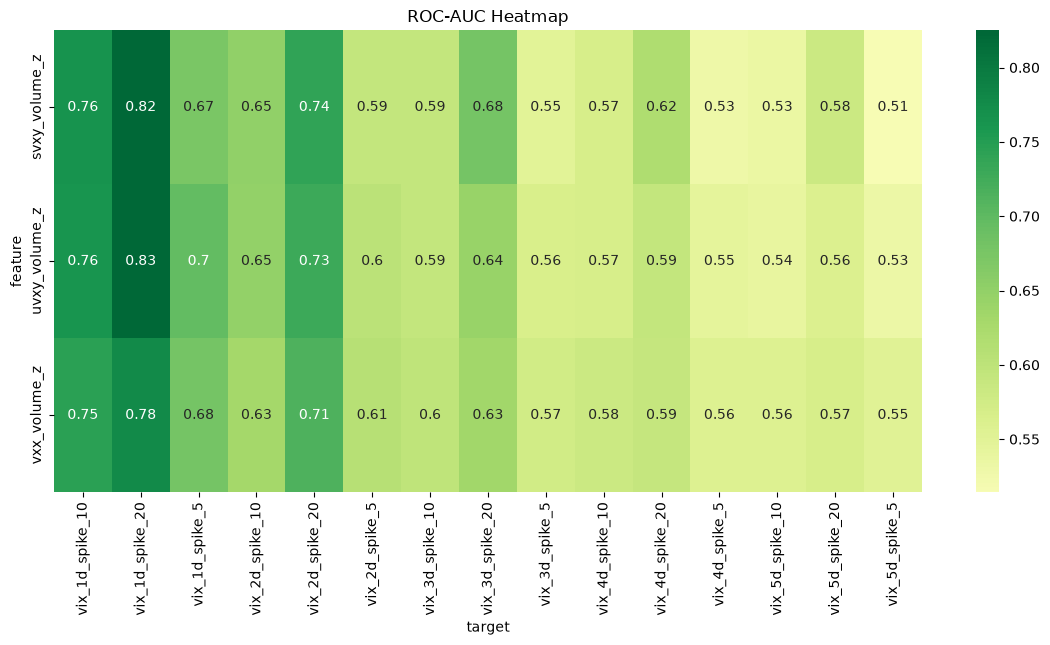

In [25]:
# ROC-AUCのヒートマップを作成
pivot_df = auc_df.pivot(
    index="feature",
    columns="target",
    values="roc_auc"
)
plt.figure(figsize=(14, 6))
# ヒートマップを描画するための準備
sns.heatmap(
    pivot_df,
    annot=True,
    cmap="RdYlGn",
    center=0.5
)
plt.title("ROC-AUC Heatmap")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"6_ROC_AUC_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()

#### 7. Logistic Regression

##### 目的

出来高から
VIX急騰確率を推定する。

In [26]:
# 1日後のVIXスパイクを予測するロジスティック回帰モデルの学習とROC-AUCの計算
TARGET_COL = "vix_1d_spike_10"
# 特徴量とターゲット列を用意
work_df = research_df[FLOW_FEATURES + [TARGET_COL]].dropna()
# 特徴量とターゲットを分ける
X = work_df[FLOW_FEATURES]
# ターゲットを用意
y = work_df[TARGET_COL]
# ロジスティック回帰モデルを作成
model = LogisticRegression(max_iter=5000)
# モデルを学習
model.fit(X, y)
# 予測確率を計算
pred_prob = model.predict_proba(X)[:, 1]
# ROC-AUCを計算
auc = roc_auc_score(y, pred_prob)
print(f"ROC-AUC = {auc:.4f}")

ROC-AUC = 0.8140


#### 8. 係数確認

##### 目的

どのETF出来高が
急騰確率へ寄与しているか確認する。

In [27]:
# モデルの係数をデータフレームにまとめて表示
coef_df = pd.DataFrame({
    "feature": FLOW_FEATURES,
    "coef": model.coef_[0]
})
# 係数を降順にソート
coef_df = coef_df.sort_values("coef", ascending=False)
display(coef_df)

,feature,coef
0,uvxy_volume_z,0.508828
1,svxy_volume_z,0.499503
2,vxx_volume_z,-0.016955


#### 9. Lift分析

##### 目的

高シグナル領域で
急騰発生率が増加するか確認する。

In [28]:
# デシルごとの平均ターゲット値を計算してリフト表を作成
lift_df = pd.DataFrame({
    "proba": pred_prob,
    "target": y
})
# 予測確率をデシルに分ける
lift_df["decile"] = pd.qcut(lift_df["proba"], 10, labels=False)
# デシルごとの平均ターゲット値を計算
lift_summary = (
    lift_df.groupby("decile")["target"]
    .mean()
    .reset_index()
    .sort_values("decile")
)
# リフト表を表示
display(lift_summary)

,decile,target
0,0,0.004878
1,1,0.024390
2,2,0.019608
3,3,0.048780
4,4,0.019512
5,5,0.053922
6,6,0.078049
7,7,0.088235
8,8,0.204878
9,9,0.395122


#### 10. Lift可視化

##### 目的

予測確率と
実際の急騰発生率の関係を確認する。

saved: /workspace/data/figures/10_Lift_2010-01-01_2026-10-23.png


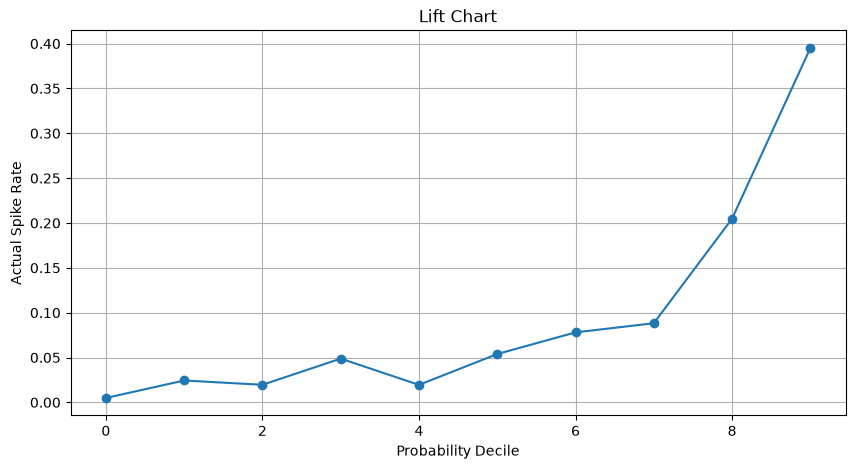

In [29]:
# リフトチャートを作成
plt.figure(figsize=(10, 5))
plt.plot(
    lift_summary["decile"],
    lift_summary["target"],
    marker="o"
)
plt.grid()
plt.title("Lift Chart")
plt.xlabel("Probability Decile")
plt.ylabel("Actual Spike Rate")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"10_Lift_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()